# 04 — Evaluation on the test set, statistical tests, convergence curves, error analysis, demo
MAS Lab 2 — Fake news detection (WCO + MOA)

**Inputs (Add Input):** `03_optimization_runs` (folder `results/`) and `02b_features` (folder `features/`). **Accelerator:** GPU T4.

The **test set (3,060 news) is used here for the first and only time**: each run's best hyperparameters are trained once on all train rows and evaluated on the test rows.

**Internet: ON** (section 10 downloads the two encoders for the demo).

## 0. Setup and inputs

In [1]:
import os, glob, json, time
import numpy as np
import pandas as pd
import torch
from xgboost import XGBClassifier

SEED = 42
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
OUT = '/kaggle/working/eval'
os.makedirs(OUT, exist_ok=True)
METHODS = ['random', 'wco', 'moa', 'wco_moa']
NAMES = {'random': 'Random search', 'wco': 'WCO', 'moa': 'MOA', 'wco_moa': 'WCO→MOA', 'default': 'XGBoost default'}

found = glob.glob('/kaggle/input/**/X_text_pca.npy', recursive=True)
assert found, 'attach the 02b_features output'
FEAT = os.path.dirname(found[0])
X_text = np.load(f'{FEAT}/X_text_pca.npy')
X_img  = np.load(f'{FEAT}/X_image_pca.npy')
X_kg   = np.load(f'{FEAT}/X_knowledge_pca.npy')
has_im = np.load(f'{FEAT}/has_image.npy').reshape(-1, 1)
y      = np.load(f'{FEAT}/y.npy').astype(int)
is_tr  = np.load(f'{FEAT}/is_train.npy')
meta   = pd.read_pickle(f'{FEAT}/meta.pkl')

X = np.hstack([X_text, X_img, X_kg, has_im]).astype(np.float32)
X_tr, X_te, y_tr, y_te = X[is_tr], X[~is_tr], y[is_tr], y[~is_tr]
meta_te = meta[~is_tr].reset_index(drop=True)
print('train', X_tr.shape, '| test', X_te.shape, '| test fake/real', np.bincount(y_te))

files = sorted(glob.glob('/kaggle/input/**/results/*_run*.json', recursive=True))
assert files, 'attach the 03_optimization_runs output'
runs = pd.DataFrame([json.load(open(f)) for f in files])
runs['cv_f1'] = 1 - runs['best_f']
print(runs.groupby('method')['run'].count().rename('runs found'))

train (12238, 225) | test (3060, 225) | test fake/real [1599 1461]
method
moa        30
random     30
wco        30
wco_moa    30
Name: runs found, dtype: int64


## 1. Evaluation function (all metrics required by the lab)

In [2]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, log_loss, confusion_matrix)

def evaluate(model, Xtr, ytr, Xte, yte):
    """Train on (Xtr, ytr), predict Xte, return the metrics + predicted probabilities."""
    t = time.time(); model.fit(Xtr, ytr); t_train = time.time() - t
    t = time.time(); proba = model.predict_proba(Xte)[:, 1]; t_test = time.time() - t
    pred = (proba >= 0.5).astype(int)
    p = np.clip(proba.astype(np.float64), 1e-12, 1 - 1e-12)
    shannon = float(np.mean(-(p * np.log2(p) + (1 - p) * np.log2(1 - p))))
    return {
        'accuracy':  accuracy_score(yte, pred),
        'precision': precision_score(yte, pred, average='macro'),
        'recall':    recall_score(yte, pred, average='macro'),
        'f1':        f1_score(yte, pred, average='macro'),
        'roc_auc':   roc_auc_score(yte, proba),
        'cross_entropy': log_loss(yte, p),
        'shannon_entropy': shannon,
        'train_time_s': t_train,
        'test_time_s':  t_test,
    }, proba

def xgb(params=None):
    """XGBoost with given hyperparameters (None = XGBoost defaults), same settings as in notebook 03."""
    return XGBClassifier(**(params or {}), tree_method='hist', device=DEV, eval_metric='logloss',
                         random_state=SEED, n_jobs=4, verbosity=0)

## 2. Final evaluation on the test set
For every run: train XGBoost once on **all train rows** with the run's best hyperparameters, evaluate on the **test rows**.

In [3]:
rows = []
for _, r in runs.iterrows():
    m, _ = evaluate(xgb(r['best_params']), X_tr, y_tr, X_te, y_te)
    rows.append({'method': r['method'], 'run': r['run'], 'cv_f1': r['cv_f1'], **m})
res = pd.DataFrame(rows)

m_def, proba_def = evaluate(xgb(), X_tr, y_tr, X_te, y_te)
default_row = {'method': 'default', 'run': 0, **m_def}
print(f'{len(res)} runs evaluated + default XGBoost')

120 runs evaluated + default XGBoost


## 3. Results table (mean ± std over the runs)

In [4]:
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'cross_entropy', 'shannon_entropy',
           'train_time_s', 'test_time_s']
table = res.groupby('method')[['cv_f1'] + metrics].agg(['mean', 'std'])
summary = pd.DataFrame({c: table[c]['mean'].map('{:.4f}'.format) + ' ± ' + table[c]['std'].map('{:.4f}'.format)
                        for c in ['cv_f1'] + metrics})
summary.loc['default'] = ['—'] + [f'{default_row[c]:.4f}' for c in metrics]
summary = summary.loc[METHODS + ['default']].rename(index=NAMES)
summary.to_csv(f'{OUT}/results_table.csv')
summary

,cv_f1,accuracy,precision,recall,f1,roc_auc,cross_entropy,shannon_entropy,train_time_s,test_time_s
method,,,,,,,,,,
Random search,0.7258 ± 0.0012,0.7400 ± 0.0035,0.7404 ± 0.0037,0.7380 ± 0.0034,0.7384 ± 0.0034,0.8172 ± 0.0033,0.5196 ± 0.0053,0.7696 ± 0.0361,4.1281 ± 1.6834,0.0237 ± 0.0027
WCO,0.7266 ± 0.0015,0.7411 ± 0.0032,0.7415 ± 0.0033,0.7392 ± 0.0032,0.7396 ± 0.0032,0.8176 ± 0.0021,0.5193 ± 0.0032,0.7652 ± 0.0368,3.8758 ± 1.6626,0.0246 ± 0.0034
MOA,0.7267 ± 0.0019,0.7411 ± 0.0039,0.7415 ± 0.0039,0.7392 ± 0.0040,0.7397 ± 0.0040,0.8178 ± 0.0033,0.5213 ± 0.0068,0.7510 ± 0.0644,4.4506 ± 2.3181,0.0243 ± 0.0043
WCO→MOA,0.7270 ± 0.0019,0.7405 ± 0.0031,0.7409 ± 0.0032,0.7386 ± 0.0030,0.7390 ± 0.0030,0.8172 ± 0.0030,0.5202 ± 0.0047,0.7685 ± 0.0419,4.4773 ± 1.7440,0.0254 ± 0.0034
XGBoost default,—,0.7167,0.7161,0.7160,0.7160,0.7905,0.5734,0.6531,0.8483,0.0114


## 4. Statistical tests
On the 30 test macro-F1 values per method (paired by run: run *r* uses the same seed for every method).
- **Shapiro-Wilk**: are the values normally distributed?
- **Friedman**: is there any difference among the 4 methods?
- **Wilcoxon signed-rank** (WCO→MOA vs each other method) with **Holm** correction for multiple comparisons
- **Cliff's delta**: effect size (how big the difference is)

In [5]:
from scipy import stats

def cliffs_delta(a, b):
    """Share of pairs where a > b minus share where a < b (from -1 to 1)."""
    a, b = np.asarray(a), np.asarray(b)
    gt = (a[:, None] > b[None, :]).sum(); lt = (a[:, None] < b[None, :]).sum()
    return (gt - lt) / (len(a) * len(b))

def magnitude(d):
    d = abs(d)
    return 'negligible' if d < 0.147 else 'small' if d < 0.33 else 'medium' if d < 0.474 else 'large'

def holm(pvals):
    """Holm step-down adjusted p-values."""
    p = np.asarray(pvals, dtype=float); order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

SUMMARY = {}

def run_tests(metric, label):
    piv = res.pivot(index='run', columns='method', values=metric)[METHODS].dropna()
    print(f'===== {label} ({len(piv)} paired runs) =====')
    print('Shapiro-Wilk (p < 0.05 -> not normal):')
    for m in METHODS:
        if piv[m].std() == 0:
            print(f'  {NAMES[m]:14s} constant values (test not applicable)'); continue
        print(f'  {NAMES[m]:14s} p = {stats.shapiro(piv[m]).pvalue:.4f}')
    fr = stats.friedmanchisquare(*[piv[m] for m in METHODS])
    ranks = piv[METHODS].rank(axis=1, ascending=False).mean()
    SUMMARY[label] = {'n_runs': len(piv),
                      'shapiro_p': {m: (float(stats.shapiro(piv[m]).pvalue) if piv[m].std() > 0 else None) for m in METHODS},
                      'friedman_chi2': float(fr.statistic), 'friedman_p': float(fr.pvalue),
                      'mean_rank': {m: float(ranks[m]) for m in METHODS}}
    print('Mean ranks (1 = best):', ' · '.join(f'{NAMES[m]} {ranks[m]:.2f}' for m in METHODS))
    print(f'Friedman: chi2 = {fr.statistic:.3f}, p = {fr.pvalue:.4g}  -> '
          f'{"significant difference" if fr.pvalue < 0.05 else "no significant difference"} among methods')
    out = []
    for m in [x for x in METHODS if x != 'wco_moa']:
        try:
            p = stats.wilcoxon(piv['wco_moa'], piv[m]).pvalue
        except ValueError:
            p = 1.0
        d = cliffs_delta(piv['wco_moa'], piv[m])
        out.append({'comparison': f'WCO→MOA vs {NAMES[m]}', 'mean diff': piv['wco_moa'].mean() - piv[m].mean(),
                    'wilcoxon p': p, 'cliffs delta': d, 'effect': magnitude(d)})
    out = pd.DataFrame(out)
    out['holm p'] = holm(out['wilcoxon p'])
    out['significant (holm < 0.05)'] = out['holm p'] < 0.05
    return out.round(4)

tests_test = run_tests('f1', 'Test macro-F1')
display(tests_test)
tests_cv = run_tests('cv_f1', 'CV macro-F1 (search objective)')
display(tests_cv)
tests_test.to_csv(f'{OUT}/stats_test_f1.csv', index=False)
tests_cv.to_csv(f'{OUT}/stats_cv_f1.csv', index=False)
json.dump(SUMMARY, open(f'{OUT}/stats_summary.json', 'w'), indent=2)
res.to_csv(f'{OUT}/per_run_results.csv', index=False)
print('saved stats_summary.json and per_run_results.csv')

===== Test macro-F1 (30 paired runs) =====
Shapiro-Wilk (p < 0.05 -> not normal):
  Random search  p = 0.9569
  WCO            p = 0.4498
  MOA            p = 0.9645
  WCO→MOA        p = 0.8434
Mean ranks (1 = best): Random search 2.77 · WCO 2.30 · MOA 2.23 · WCO→MOA 2.70
Friedman: chi2 = 4.054, p = 0.2557  -> no significant difference among methods


,comparison,mean diff,wilcoxon p,cliffs delta,effect,holm p,significant (holm < 0.05)
0,WCO→MOA vs Random search,0.0006,0.5978,0.0967,negligible,1.0,False
1,WCO→MOA vs WCO,-0.0006,0.3409,-0.1356,negligible,1.0,False
2,WCO→MOA vs MOA,-0.0006,0.6263,-0.0844,negligible,1.0,False


===== CV macro-F1 (search objective) (30 paired runs) =====
Shapiro-Wilk (p < 0.05 -> not normal):
  Random search  p = 0.3080
  WCO            p = 0.2680
  MOA            p = 0.1536
  WCO→MOA        p = 0.7573
Mean ranks (1 = best): Random search 3.07 · WCO 2.40 · MOA 2.33 · WCO→MOA 2.20
Friedman: chi2 = 8.189, p = 0.04226  -> significant difference among methods


,comparison,mean diff,wilcoxon p,cliffs delta,effect,holm p,significant (holm < 0.05)
0,WCO→MOA vs Random search,0.0012,0.0113,0.4200,medium,0.0339,True
1,WCO→MOA vs WCO,0.0004,0.2376,0.1756,small,0.4752,False
2,WCO→MOA vs MOA,0.0003,0.8236,0.0556,negligible,0.8236,False


saved stats_summary.json and per_run_results.csv


## 5. Convergence curves (mean of the runs ± 95% confidence interval)
Best fitness = best (lowest) 1 − F1 found so far; average fitness = moving average of the evaluated solutions.
The vertical line marks the switch from WCO (exploration) to MOA (exploitation) in the hybrid.

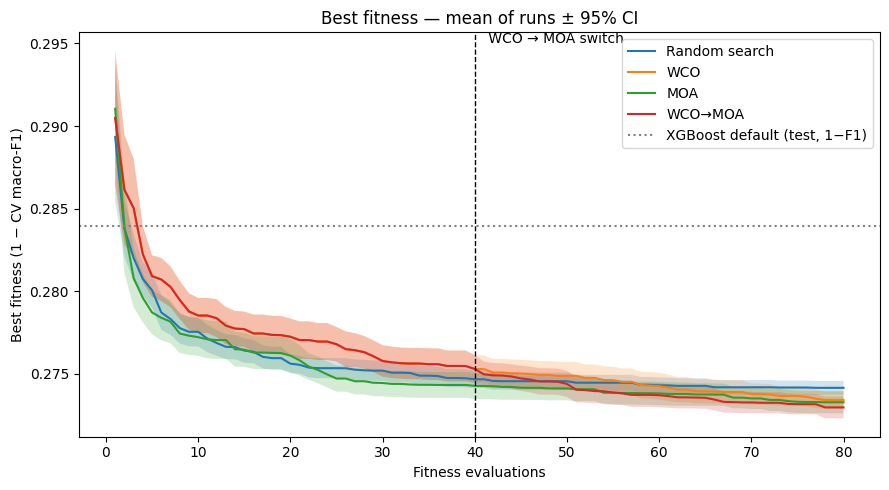

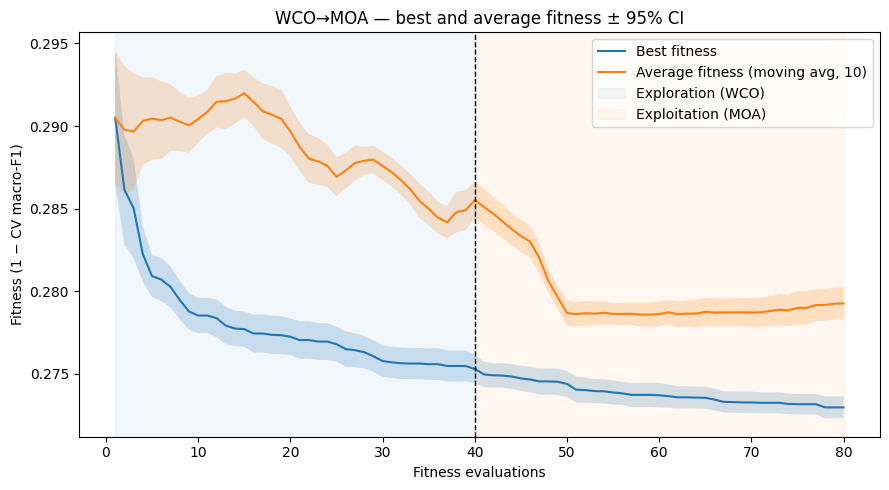

In [6]:
import matplotlib.pyplot as plt

def curves(method, key):
    A = np.array([h for h in runs.loc[runs['method'] == method, key]], dtype=float)
    if key == 'values':
        A = np.array([pd.Series(a).rolling(10, min_periods=1).mean().to_numpy() for a in A])
    mean = A.mean(0); ci = 1.96 * A.std(0, ddof=1) / np.sqrt(len(A))
    return mean, ci

switch = int(np.median([s.get('switch_eval', 0) for s in runs.loc[runs['method'] == 'wco_moa', 'stats']]))
x = np.arange(1, len(runs['best_history'].iloc[0]) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
for m in METHODS:
    mean, ci = curves(m, 'best_history')
    ax.plot(x, mean, label=NAMES[m]); ax.fill_between(x, mean - ci, mean + ci, alpha=0.2)
ax.axhline(1 - m_def['f1'], color='gray', ls=':', label='XGBoost default (test, 1−F1)')
ax.axvline(switch, color='k', ls='--', lw=1); ax.text(switch + 1, ax.get_ylim()[1], ' WCO → MOA switch', va='top')
ax.set(xlabel='Fitness evaluations', ylabel='Best fitness (1 − CV macro-F1)', title='Best fitness — mean of runs ± 95% CI')
ax.legend(); fig.tight_layout(); fig.savefig(f'{OUT}/convergence_best_all.png', dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
for key, lab in [('best_history', 'Best fitness'), ('values', 'Average fitness (moving avg, 10)')]:
    mean, ci = curves('wco_moa', key)
    ax.plot(x, mean, label=lab); ax.fill_between(x, mean - ci, mean + ci, alpha=0.2)
ax.axvspan(1, switch, color='tab:blue', alpha=0.06, label='Exploration (WCO)')
ax.axvspan(switch, x[-1], color='tab:orange', alpha=0.06, label='Exploitation (MOA)')
ax.axvline(switch, color='k', ls='--', lw=1)
ax.set(xlabel='Fitness evaluations', ylabel='Fitness (1 − CV macro-F1)', title='WCO→MOA — best and average fitness ± 95% CI')
ax.legend(); fig.tight_layout(); fig.savefig(f'{OUT}/convergence_hybrid.png', dpi=150); plt.show()

## 6. Final model and comparison with other ML models
Final model = WCO→MOA run with the best CV fitness. Other models are trained with standard settings on the same features.

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

best_run = runs[runs['method'] == 'wco_moa'].sort_values('best_f').iloc[0]
BEST_PARAMS = best_run['best_params']
print('Final hyperparameters (WCO→MOA, run', best_run['run'], '):', BEST_PARAMS)
json.dump(BEST_PARAMS, open(f'{OUT}/best_params.json', 'w'), indent=2)

models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'KNN (k=15)':          make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'Random forest':       RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    'XGBoost default':     xgb(),
    'XGBoost + WCO→MOA':   xgb(BEST_PARAMS),
}
comp, probas = [], {}
for name, model in models.items():
    m, probas[name] = evaluate(model, X_tr, y_tr, X_te, y_te)
    comp.append({'model': name, **m})
comp = pd.DataFrame(comp).set_index('model').round(4)
comp.to_csv(f'{OUT}/model_comparison.csv')
comp

Final hyperparameters (WCO→MOA, run 17 ): {'n_estimators': 600, 'learning_rate': 0.02247166992951017, 'max_depth': 9, 'min_child_weight': 7.367821478661812, 'subsample': 0.5, 'colsample_bytree': 0.8849133906713627, 'gamma': 1.0861510705225244, 'reg_alpha': 0.8231066911428652, 'reg_lambda': 0.2785837738006366}


,accuracy,precision,recall,f1,roc_auc,cross_entropy,shannon_entropy,train_time_s,test_time_s
model,,,,,,,,,
Logistic regression,0.7281,0.7281,0.7263,0.7267,0.7972,0.5434,0.7671,0.1957,0.0152
KNN (k=15),0.6739,0.6808,0.6774,0.6731,0.7551,0.5991,0.8141,0.0860,0.4110
Random forest,0.7255,0.7287,0.7219,0.7220,0.7965,0.5764,0.9290,31.3399,0.1198
XGBoost default,0.7167,0.7161,0.7160,0.7160,0.7905,0.5734,0.6531,1.0137,0.0103
XGBoost + WCO→MOA,0.7415,0.7421,0.7394,0.7399,0.8203,0.5150,0.7562,5.0562,0.0289


## 7. Ablation: which features matter?
The final hyperparameters trained on text only, text + image, and text + image + knowledge.

In [8]:
variants = {
    'A: text':                       X_text,
    'B: text + image':               np.hstack([X_text, X_img, has_im]),
    'C: text + image + knowledge':   X,
}
abl = []
for name, Xv in variants.items():
    Xv = Xv.astype(np.float32)
    m, _ = evaluate(xgb(BEST_PARAMS), Xv[is_tr], y_tr, Xv[~is_tr], y_te)
    abl.append({'features': name, 'n_features': Xv.shape[1], **m})
abl = pd.DataFrame(abl).set_index('features').round(4)
abl.to_csv(f'{OUT}/ablation.csv')
abl

,n_features,accuracy,precision,recall,f1,roc_auc,cross_entropy,shannon_entropy,train_time_s,test_time_s
features,,,,,,,,,,
A: text,128,0.7163,0.7172,0.7138,0.7141,0.7822,0.5584,0.8065,3.5592,0.0249
B: text + image,193,0.7356,0.7361,0.7335,0.7339,0.8144,0.5213,0.7594,4.6017,0.0287
C: text + image + knowledge,225,0.7415,0.7421,0.7394,0.7399,0.8203,0.5150,0.7562,5.0855,0.0294


## 8. Error analysis (final model)

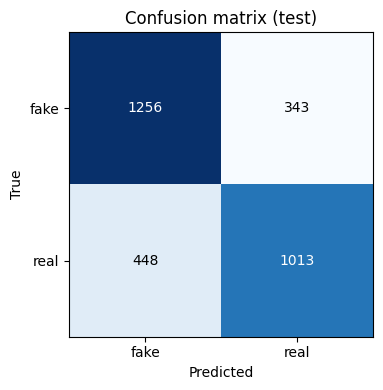

,n,accuracy,real_share
platform,,,
twitter,156,0.647,0.385
washingtonpost,193,0.653,0.679
snope,1530,0.676,0.307
apnews,141,0.844,0.943
cnn,493,0.848,0.909
reddit,511,0.851,0.358
cdc_gov,36,0.972,1.000


,n,accuracy
fine_label,,
real,1461,0.693
text–image inconsistency,243,0.774
content–knowledge inconsistency,274,0.759
text-based fake,722,0.789
image-based fake,298,0.916
others,62,0.274


,n,accuracy
has_image,,
False,20,1.00
True,3040,0.74


[true=fake | pred=real | snope | text–image inconsistency] The sound of a witness farting loudly during testimony in the Johnny Depp v. Amber Heard defamation trial was captured on video.
[true=real | pred=fake | cnn | real] Whatever It Is, It's Probably Not Hair DyeRudolph W. Giuliani gave a news conference on Thursday in which, as he continued to cast doubt on the result
[true=real | pred=fake | snope | real] A photograph shows a pizzly bear, the offspring of a polar bear and a grizzly bear.
[true=fake | pred=real | snope | text-based fake] Online advertisements linked users to a website revealing Tom Selleck's final words before "leaving the stage forever" and that he will never again st
[true=real | pred=fake | reddit | real] The Rashidun Caliphate


In [9]:
proba = probas['XGBoost + WCO→MOA']
pred = (proba >= 0.5).astype(int)
cm = confusion_matrix(y_te, pred)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha='center', va='center', color='white' if v > cm.max() / 2 else 'black')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['fake', 'real'], yticklabels=['fake', 'real'],
       xlabel='Predicted', ylabel='True', title='Confusion matrix (test)')
fig.tight_layout(); fig.savefig(f'{OUT}/confusion_matrix.png', dpi=150); plt.show()

err = meta_te.assign(true=y_te, pred=pred, correct=(pred == y_te))
FINE = {0: 'real', 1: 'text–image inconsistency', 2: 'content–knowledge inconsistency',
        3: 'text-based fake', 4: 'image-based fake', 5: 'others'}
by_platform = err.groupby('platform').agg(n=('correct', 'size'), accuracy=('correct', 'mean'),
                                          real_share=('true', 'mean')).sort_values('accuracy').round(3)
by_fine = err.groupby('fine_label').agg(n=('correct', 'size'), accuracy=('correct', 'mean')).round(3)
by_fine.index = by_fine.index.map(FINE)
by_image = err.groupby('has_image').agg(n=('correct', 'size'), accuracy=('correct', 'mean')).round(3)
by_platform.to_csv(f'{OUT}/errors_by_platform.csv'); by_fine.to_csv(f'{OUT}/errors_by_fine_label.csv')
display(by_platform); display(by_fine); display(by_image)

wrong = err[~err['correct']].sample(min(5, (~err['correct']).sum()), random_state=SEED)
for _, r in wrong.iterrows():
    print(f"[true={'real' if r.true else 'fake'} | pred={'real' if r.pred else 'fake'} | {r.platform} | {FINE[r.fine_label]}] {r.text_clean[:150]}")

## 9. Demo: predict a new news item (multimodal model A)
`predict(text, image=None)` — a new text (and optionally an image: file path or URL) goes through **the same steps as the training data**:
text → same cleaning → `all-mpnet-base-v2` (768) · image → `clip-ViT-B-32` (512, zeros if no image) · knowledge → zeros (a new post has no knowledge-graph vector, like training rows where no entity was found) → **the same 3 PCAs** (rebuilt from the train rows with the same seed as 02b and checked against the saved features) → 225 numbers → final XGBoost → P(real) → FAKE / REAL.

**Needs Internet ON** (downloads the two encoders). Limitation: without a knowledge vector the model uses only text + image for a new post.

In [10]:
!pip install -q sentence-transformers
import re, html, io, requests
from PIL import Image
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer

raw   = {'text': np.load(f'{FEAT}/X_text.npy'), 'image': np.load(f'{FEAT}/X_img.npy'), 'knowledge': np.load(f'{FEAT}/X_kg.npy')}
saved = {'text': X_text, 'image': X_img, 'knowledge': X_kg}
PCAS = {}
for name, Xr in raw.items():
    PCAS[name] = PCA(n_components=saved[name].shape[1], random_state=SEED).fit(Xr[is_tr])
    gap = np.abs(PCAS[name].transform(Xr).astype(np.float32) - saved[name]).max()
    print(f'{name:9s} PCA rebuilt | max difference with the saved features: {gap:.2e}', '' if gap < 1e-3 else '  <-- CHECK')

text_enc = SentenceTransformer('all-mpnet-base-v2', device=DEV); text_enc.max_seq_length = 384
img_enc  = SentenceTransformer('clip-ViT-B-32', device=DEV)
detector = models['XGBoost + WCO→MOA']
KG_ZERO  = np.zeros((1, raw['knowledge'].shape[1]), dtype=np.float32)
IMG_ZERO = np.zeros((1, raw['image'].shape[1]), dtype=np.float32)

def clean_news(t):
    t = html.unescape(str(t))
    t = re.sub(r'<[^>]+>', ' ', t)
    for k, v in {'’': "'", '‘': "'", '“': '"', '”': '"', '–': '-', '—': '-'}.items():
        t = t.replace(k, v)
    t = re.sub(r'https?://\S+|www\.\S+', ' [URL] ', t)
    t = re.sub(r'@\w+', ' ', t)
    t = re.sub(r'#(\w+)', r'\1', t)
    return re.sub(r'\s+', ' ', t).strip()

def load_image(src):
    try:
        im = Image.open(io.BytesIO(requests.get(src, timeout=15).content)) if str(src).startswith('http') else Image.open(src)
        im = im.convert('RGB'); im.thumbnail((448, 448))
        return im
    except Exception as e:
        print('   (image not usable -> treated as no image:', type(e).__name__, ')')
        return None

def predict(text, image=None):
    """text (+ optional image path/URL) -> ('FAKE'/'REAL', P(fake)). Same features and order as training: text | image | knowledge | has_image."""
    v_txt = text_enc.encode([clean_news(text)], normalize_embeddings=True)
    im = load_image(image) if image is not None else None
    v_img = img_enc.encode([im], normalize_embeddings=True) if im is not None else IMG_ZERO
    x = np.hstack([PCAS['text'].transform(v_txt), PCAS['image'].transform(v_img),
                   PCAS['knowledge'].transform(KG_ZERO), [[1.0 if im is not None else 0.0]]]).astype(np.float32)
    p_real = float(detector.predict_proba(x)[0, 1])
    verdict = 'REAL' if p_real >= 0.5 else 'FAKE'
    print(f"{verdict:4s}  (P(fake) = {1 - p_real:.2f})  {'[text + image]' if im is not None else '[text only]'}  ←  {text[:110]}")
    return verdict, 1 - p_real

demo = []
DEMO_TEXTS = ['Scientists confirm that drinking bleach cures the flu, doctors stunned',
              'The Federal Reserve raised interest rates by a quarter point on Wednesday',
              'BREAKING: Famous actor secretly replaced by body double, insiders reveal',
              'City council approves new budget for public schools after long debate']
for t in DEMO_TEXTS:
    v, pf = predict(t); demo.append({'input': 'new text', 'text': t, 'image': None, 'truth': None, 'pred': v, 'p_fake': round(pf, 4)})

import glob as _g
_dirs = _g.glob('/kaggle/input/**/finefake/Image', recursive=True)
if _dirs:
    _new = _dirs[0]
    meta_te['image_full'] = meta_te['image_full'].apply(
        lambda p: _new + p.split('finefake/Image', 1)[1] if isinstance(p, str) and 'finefake/Image' in p else p)
    print('FineFake images found in:', _new)
img_test = [i for i in np.where(meta_te['has_image'].to_numpy().astype(bool))[0] if isinstance(meta_te['image_full'].iat[i], str) and os.path.exists(meta_te['image_full'].iat[i])]
if img_test:
    rng = np.random.default_rng(SEED)
    for i in rng.choice(img_test, size=min(4, len(img_test)), replace=False):
        r = meta_te.iloc[i]; truth = 'REAL' if y_te[i] == 1 else 'FAKE'
        v, pf = predict(r['text_clean'], r['image_full'])
        print(f'      truth: {truth} · platform: {r["platform"]}')
        demo.append({'input': 'test item', 'text': r['text_clean'][:200], 'image': r['image_full'], 'truth': truth, 'pred': v, 'p_fake': round(pf, 4)})
else:
    print('(FineFake images not attached -> no image demo on test items; text demo above is complete)')
pd.DataFrame(demo).to_csv(f'{OUT}/demo_predictions.csv', index=False)

text      PCA rebuilt | max difference with the saved features: 0.00e+00 
image     PCA rebuilt | max difference with the saved features: 0.00e+00 
knowledge PCA rebuilt | max difference with the saved features: 0.00e+00 


REAL  (P(fake) = 0.08)  [text only]  ←  Scientists confirm that drinking bleach cures the flu, doctors stunned
REAL  (P(fake) = 0.05)  [text only]  ←  The Federal Reserve raised interest rates by a quarter point on Wednesday
REAL  (P(fake) = 0.18)  [text only]  ←  BREAKING: Famous actor secretly replaced by body double, insiders reveal
REAL  (P(fake) = 0.03)  [text only]  ←  City council approves new budget for public schools after long debate
FineFake images found in: /kaggle/input/notebooks/khitersaranadjet/02a-finefake-cleaning/finefake/Image
REAL  (P(fake) = 0.15)  [text + image]  ←  A letter was written by F. Scott Fitzgerald in 1920 while the author was quarantined in France during the "Spa
      truth: FAKE · platform: snope
REAL  (P(fake) = 0.10)  [text + image]  ←  When T.R. Saw LincolnLook at the open second-floor window between shutters in this photograph, and you will se
      truth: REAL · platform: cnn
REAL  (P(fake) = 0.07)  [text + image]  ←  Portland Protests: Local Le

## 10. Files produced

In [11]:
for f in sorted(os.listdir(OUT)):
    print(f'{f:32s} {os.path.getsize(f"{OUT}/{f}") / 1e3:8.1f} KB')

ablation.csv                          0.4 KB
best_params.json                      0.3 KB
confusion_matrix.png                 20.7 KB
convergence_best_all.png            111.2 KB
convergence_hybrid.png              113.6 KB
demo_predictions.csv                  1.5 KB
errors_by_fine_label.csv              0.2 KB
errors_by_platform.csv                0.2 KB
model_comparison.csv                  0.5 KB
per_run_results.csv                  23.9 KB
results_table.csv                     0.9 KB
stats_cv_f1.csv                       0.3 KB
stats_summary.json                    0.9 KB
stats_test_f1.csv                     0.3 KB
